In [31]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

In [2]:
pip install yfinance

**DOWNLOADING DATASET**

In [4]:
import yfinance as yf

df = yf.download(
    "RELIANCE.NS",
    start="2020-01-01",
    end="2026-08-01",
    auto_adjust=False
)

print(df.head())

[*********************100%***********************]  1 of 1 completed

Price        Adj Close       Close        High         Low        Open  \
Ticker     RELIANCE.NS RELIANCE.NS RELIANCE.NS RELIANCE.NS RELIANCE.NS   
Date                                                                     
2020-01-01  672.216125  690.138306  698.138733  688.263977  693.978516   
2020-01-02  683.660339  701.887512  704.470520  691.235535  691.235535   
2020-01-03  684.484070  702.733276  704.790527  696.264343  700.835999   
2020-01-06  668.609253  686.435303  698.504456  684.835205  694.892883   
2020-01-07  678.895630  696.995850  701.521790  691.921265  694.435669   

Price           Volume  
Ticker     RELIANCE.NS  
Date                    
2020-01-01    14004468  
2020-01-02    17710316  
2020-01-03    20984698  
2020-01-06    24519177  
2020-01-07    16683622  


In [5]:
df.columns = df.columns.get_level_values(0)

print(df.head())
print(df.columns)

Price        Adj Close       Close        High         Low        Open  \
Date                                                                     
2020-01-01  672.216125  690.138306  698.138733  688.263977  693.978516   
2020-01-02  683.660339  701.887512  704.470520  691.235535  691.235535   
2020-01-03  684.484070  702.733276  704.790527  696.264343  700.835999   
2020-01-06  668.609253  686.435303  698.504456  684.835205  694.892883   
2020-01-07  678.895630  696.995850  701.521790  691.921265  694.435669   

Price         Volume  
Date                  
2020-01-01  14004468  
2020-01-02  17710316  
2020-01-03  20984698  
2020-01-06  24519177  
2020-01-07  16683622  
Index(['Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume'], dtype='object', name='Price')


In [6]:
df.columns = df.columns.get_level_values(0)

In [7]:
print(df.head())

Price        Adj Close       Close        High         Low        Open  \
Date                                                                     
2020-01-01  672.216125  690.138306  698.138733  688.263977  693.978516   
2020-01-02  683.660339  701.887512  704.470520  691.235535  691.235535   
2020-01-03  684.484070  702.733276  704.790527  696.264343  700.835999   
2020-01-06  668.609253  686.435303  698.504456  684.835205  694.892883   
2020-01-07  678.895630  696.995850  701.521790  691.921265  694.435669   

Price         Volume  
Date                  
2020-01-01  14004468  
2020-01-02  17710316  
2020-01-03  20984698  
2020-01-06  24519177  
2020-01-07  16683622  


In [8]:
print(df.shape)

(1633, 6)


In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1633 entries, 2020-01-01 to 2026-07-31
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Adj Close  1633 non-null   float64
 1   Close      1633 non-null   float64
 2   High       1633 non-null   float64
 3   Low        1633 non-null   float64
 4   Open       1633 non-null   float64
 5   Volume     1633 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 89.3 KB
None


**DATA CLEANING**

In [10]:
print(df.isnull().sum())

Price
Adj Close    0
Close        0
High         0
Low          0
Open         0
Volume       0
dtype: int64


In [14]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [16]:
# Check again
print("Shape after cleaning:", df.shape)
print(df.head())

Shape after cleaning: (1633, 7)
Price        Adj Close       Close        High         Low        Open  \
Date                                                                     
2020-01-01  672.216125  690.138306  698.138733  688.263977  693.978516   
2020-01-02  683.660339  701.887512  704.470520  691.235535  691.235535   
2020-01-03  684.484070  702.733276  704.790527  696.264343  700.835999   
2020-01-06  668.609253  686.435303  698.504456  684.835205  694.892883   
2020-01-07  678.895630  696.995850  701.521790  691.921265  694.435669   

Price         Volume    Return  
Date                            
2020-01-01  14004468       NaN  
2020-01-02  17710316  0.017024  
2020-01-03  20984698  0.001205  
2020-01-06  24519177 -0.023192  
2020-01-07  16683622  0.015385  


**PLOTTING OF CLOSING PRICE**

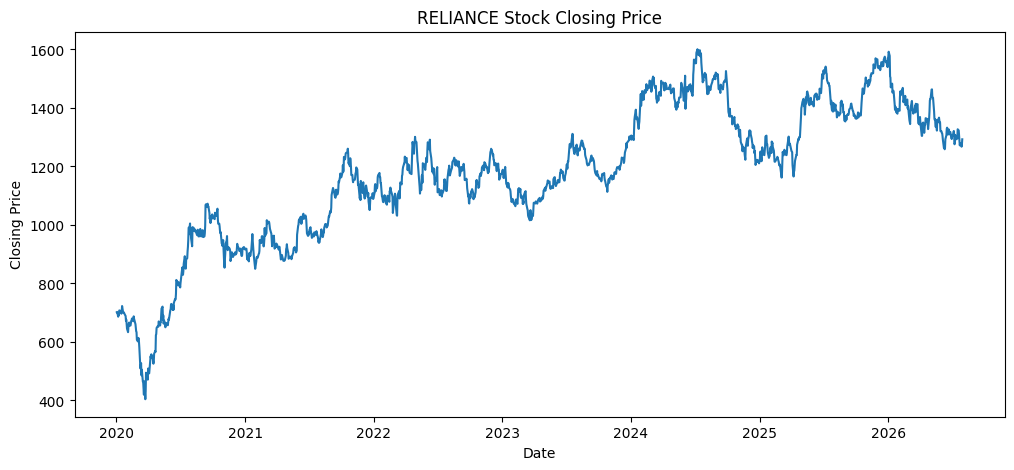

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(df.index, df["Close"])
plt.title("RELIANCE Stock Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price")
plt.show()

**CLASSIFICATION TARGET**

In [26]:
# Tomorrow's closing price
df["Next_Close"] = df["Close"].shift(-1)

# Target: 1 if tomorrow's price is higher, otherwise 0
df["Target"] = (df["Next_Close"] > df["Close"]).astype(int)

print(df[["Close", "Next_Close", "Target"]].head(10))

# Remove the final row because tomorrow's price is unavailable
df = df.iloc[:-1]

Price            Close  Next_Close  Target
Date                                      
2020-01-02  701.887512  702.733276       1
2020-01-03  702.733276  686.435303       0
2020-01-06  686.435303  696.995850       1
2020-01-07  696.995850  691.761292       0
2020-01-08  691.761292  707.693542       1
2020-01-09  707.693542  707.533508       0
2020-01-10  707.533508  705.727722       0
2020-01-13  705.727722  699.190247       0
2020-01-14  699.190247  696.652954       0
2020-01-15  696.652954  703.076111       1


In [27]:
df = df.drop(columns=["Next_Close"])

In [28]:
print(df.head())
print(df.shape)

Price        Adj Close       Close        High         Low        Open  \
Date                                                                     
2020-01-02  683.660339  701.887512  704.470520  691.235535  691.235535   
2020-01-03  684.484070  702.733276  704.790527  696.264343  700.835999   
2020-01-06  668.609253  686.435303  698.504456  684.835205  694.892883   
2020-01-07  678.895630  696.995850  701.521790  691.921265  694.435669   
2020-01-08  673.797058  691.761292  701.498901  690.321228  692.607056   

Price         Volume    Return  Target  
Date                                    
2020-01-02  17710316  0.017024       1  
2020-01-03  20984698  0.001205       0  
2020-01-06  24519177 -0.023192       1  
2020-01-07  16683622  0.015385       0  
2020-01-08  16047902 -0.007510       1  
(1631, 8)


In [29]:
X = df[["Open", "High", "Low", "Close", "Volume"]]
y = df["Target"]

**Train-Test Split**

In [30]:
split = int(len(df) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1304, 5)
Testing data: (327, 5)


**Logistic Regression**

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

logistic_pred = logistic_model.predict(X_test)

print(f"Logistic Regression Accuracy: {logistic_accuracy * 100:.2f}%")

Logistic Regression Accuracy: 49.54%


**K-Nearest Neighbors (KNN)**

In [47]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=10))
])

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print(f"KNN Accuracy: {knn_accuracy * 100:.2f}%")

KNN Accuracy: 50.15%


**Decision Tree**

In [34]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

decision_tree_model.fit(X_train, y_train)

decision_tree_pred = decision_tree_model.predict(X_test)

decision_tree_accuracy = accuracy_score(
    y_test,
    decision_tree_pred
)

print(f"Decision Tree Accuracy: {decision_tree_accuracy * 100:.2f}%")

Decision Tree Accuracy: 46.48%


**Random Forest**

In [35]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train, y_train)

random_forest_pred = random_forest_model.predict(X_test)

random_forest_accuracy = accuracy_score(
    y_test,
    random_forest_pred
)

print(f"Random Forest Accuracy: {random_forest_accuracy * 100:.2f}%")

Random Forest Accuracy: 48.93%


**Support Vector Machine (SVM)**

In [50]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print(f"SVM Accuracy: {svm_accuracy * 100:.2f}%")

SVM Accuracy: 49.54%


**Naive Bayes**

In [37]:
from sklearn.naive_bayes import GaussianNB

naive_bayes_model = GaussianNB()

naive_bayes_model.fit(X_train, y_train)

naive_bayes_pred = naive_bayes_model.predict(X_test)

naive_bayes_accuracy = accuracy_score(
    y_test,
    naive_bayes_pred
)

print(f"Naive Bayes Accuracy: {naive_bayes_accuracy * 100:.2f}%")

Naive Bayes Accuracy: 53.21%


**XGBoost**

In [38]:
!pip install -q xgboost

In [39]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=100,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

xgb_accuracy = accuracy_score(
    y_test,
    xgb_pred
)

print(f"XGBoost Accuracy: {xgb_accuracy * 100:.2f}%")

XGBoost Accuracy: 49.54%


**Comparison of Models**

In [40]:
results = {
    "Logistic Regression": logistic_accuracy * 100,
    "KNN": knn_accuracy * 100,
    "Decision Tree": decision_tree_accuracy * 100,
    "Random Forest": random_forest_accuracy * 100,
    "SVM": svm_accuracy * 100,
    "Naive Bayes": naive_bayes_accuracy * 100,
    "XGBoost": xgb_accuracy * 100
}

print(results)

{'Logistic Regression': 49.54128440366973, 'KNN': 50.15290519877675, 'Decision Tree': 46.48318042813456, 'Random Forest': 48.92966360856269, 'SVM': 49.54128440366973, 'Naive Bayes': 53.21100917431193, 'XGBoost': 49.54128440366973}


In [41]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

results_df = results_df.sort_values(
    "Accuracy",
    ascending=False
)

print(results_df)

                 Model   Accuracy
5          Naive Bayes  53.211009
1                  KNN  50.152905
0  Logistic Regression  49.541284
6              XGBoost  49.541284
4                  SVM  49.541284
3        Random Forest  48.929664
2        Decision Tree  46.483180


**Plotting**

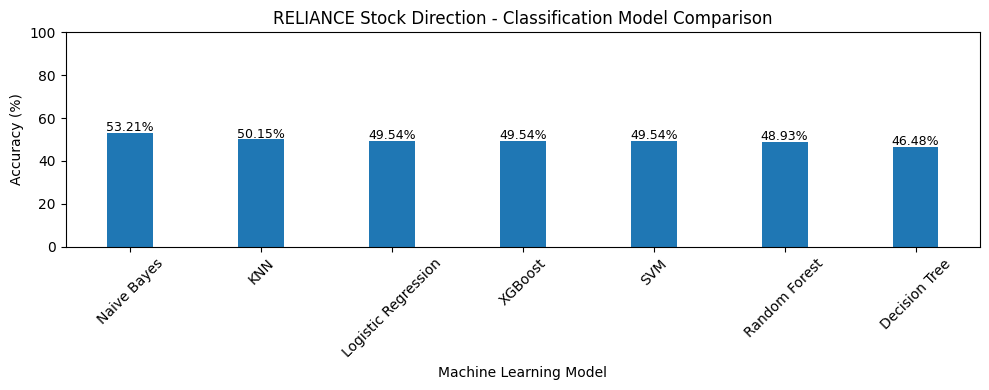

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

bars = plt.bar(
    results_df["Model"],
    results_df["Accuracy"],
    width=0.35
)

plt.title(
    "RELIANCE Stock Direction - Classification Model Comparison"
)

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45)
plt.ylim(0, 100)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.8,
        f"{height:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [43]:
best_model = results_df.iloc[0]

print(
    f"Best Model: {best_model['Model']}"
)

print(
    f"Accuracy: {best_model['Accuracy']:.2f}%"
)

Best Model: Naive Bayes
Accuracy: 53.21%


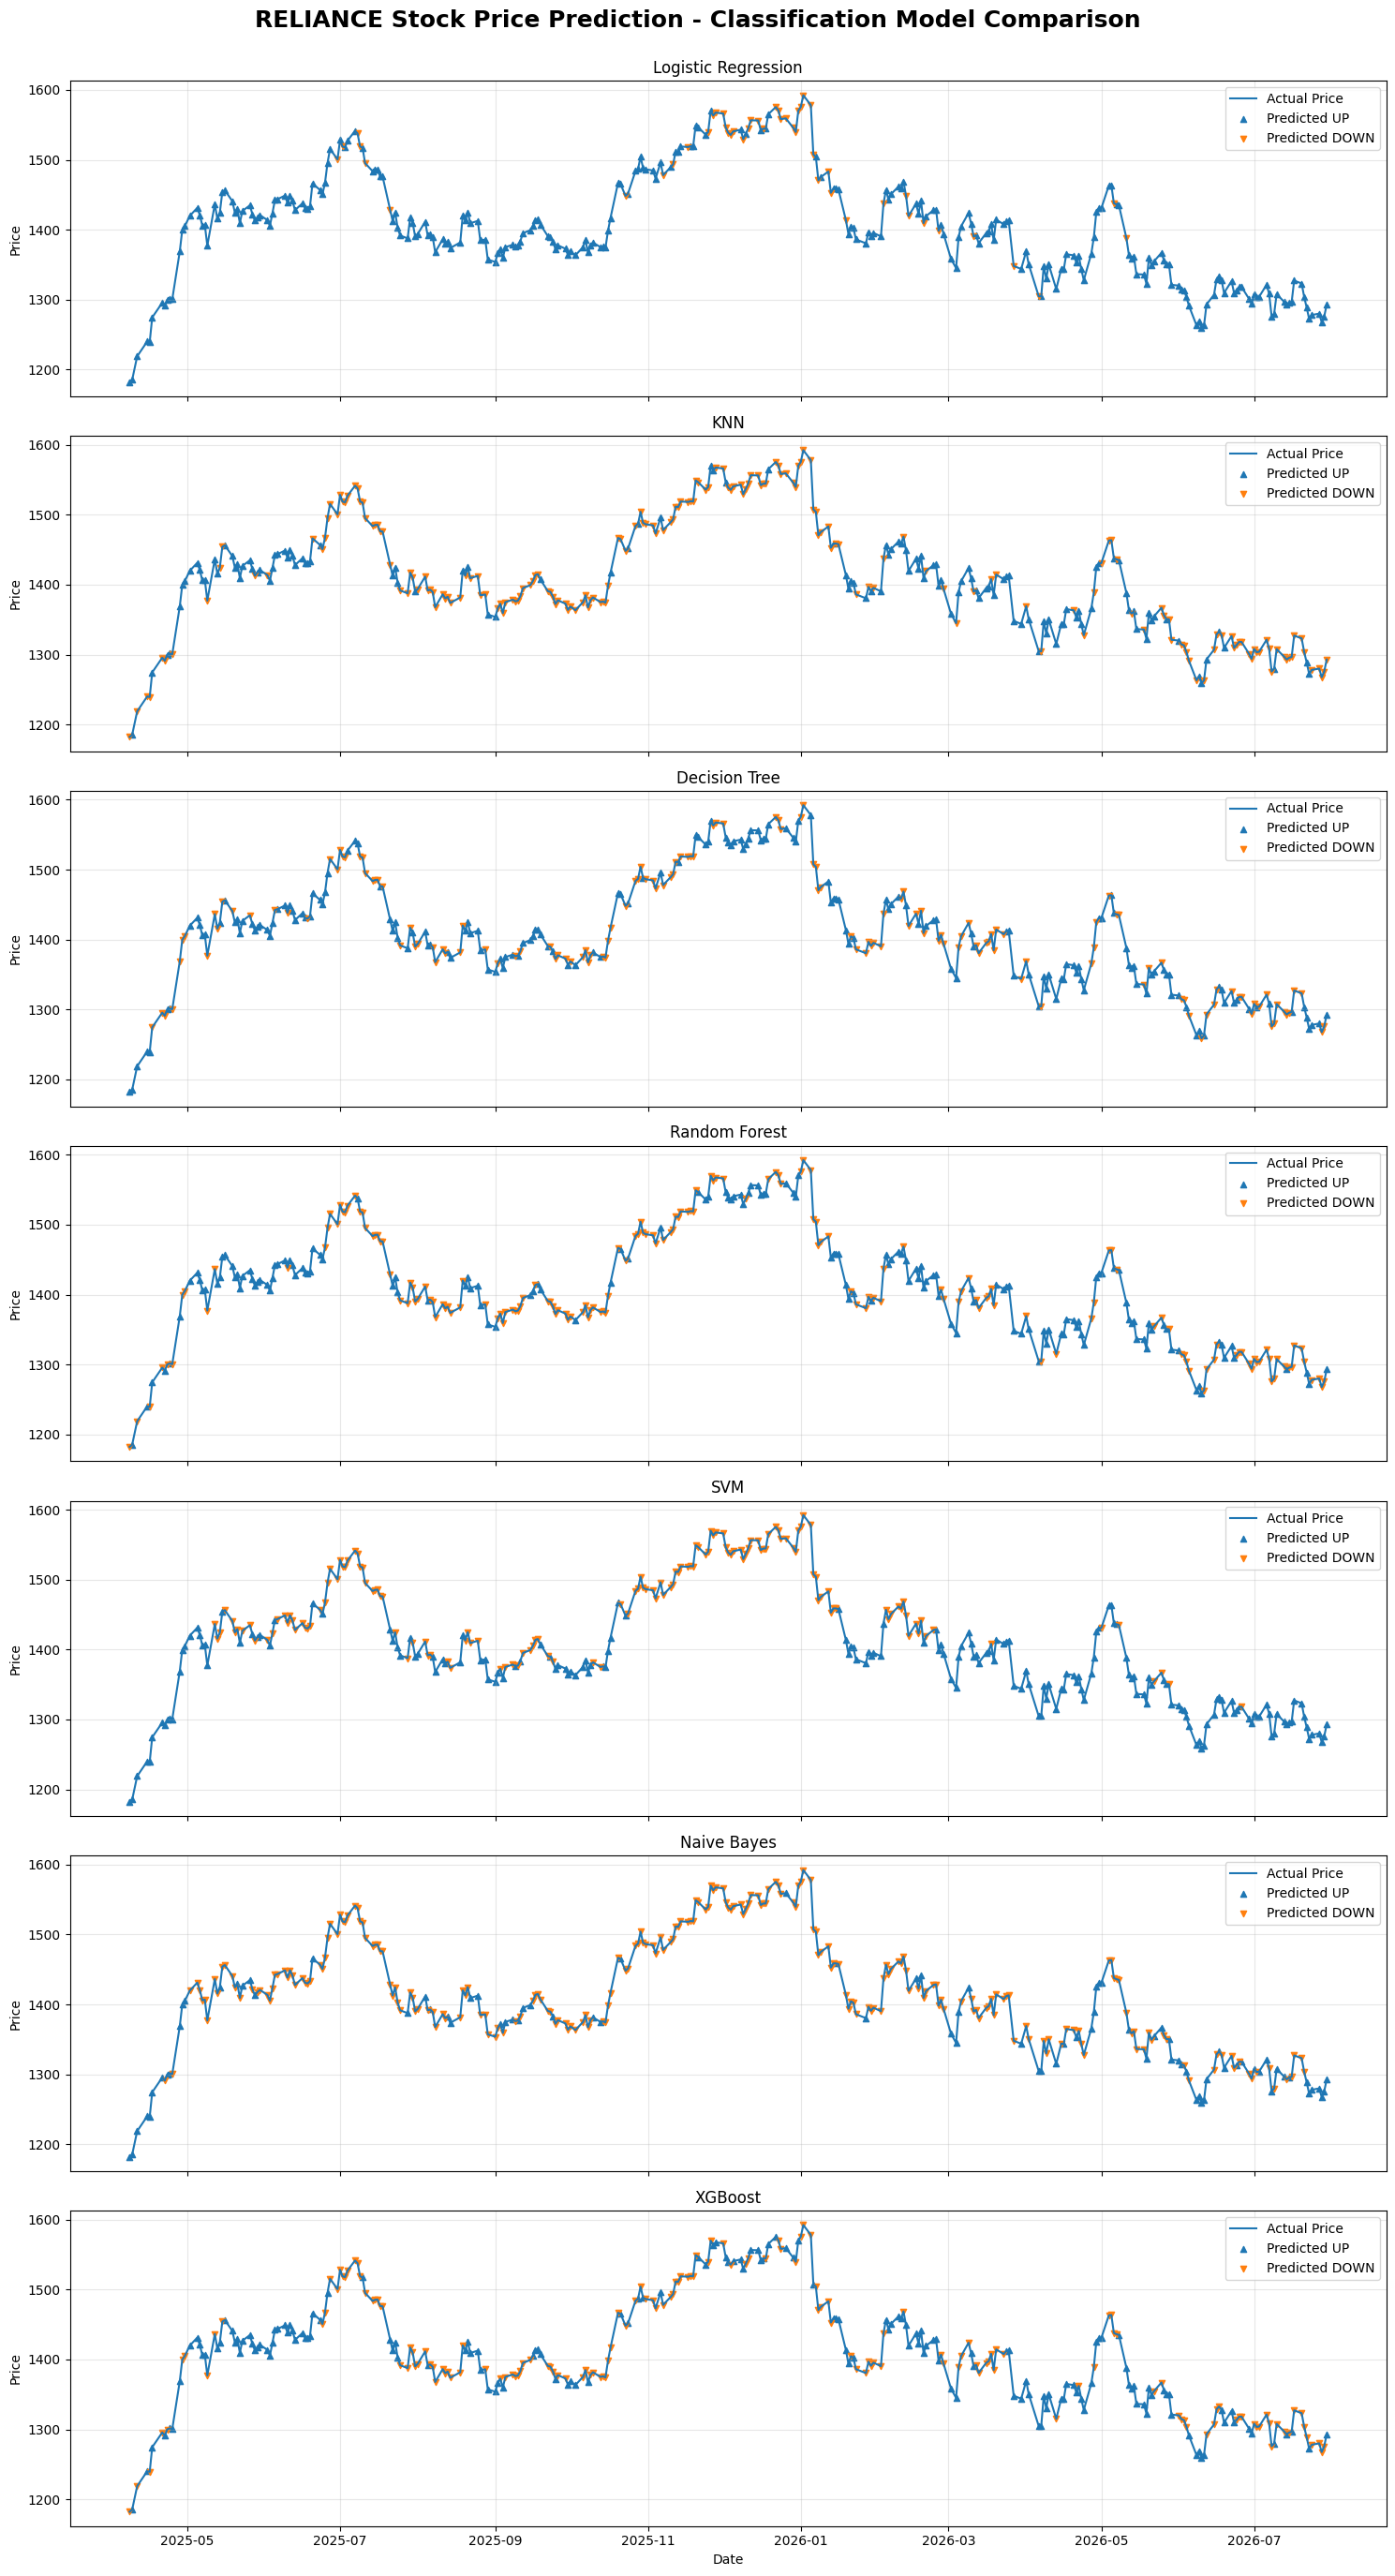

In [55]:
import matplotlib.pyplot as plt

predictions = {
    "Logistic Regression": logistic_pred,
    "KNN": knn_pred,
    "Decision Tree": decision_tree_pred,
    "Random Forest": random_forest_pred,
    "SVM": svm_pred,
    "Naive Bayes": naive_bayes_pred,
    "XGBoost": xgb_pred
}

fig, axes = plt.subplots(
    7, 1,
    figsize=(15, 28),
    sharex=True
)

for ax, (name, pred) in zip(axes, predictions.items()):

    # Actual price
    ax.plot(
        test_dates,
        test_prices,
        label="Actual Price"
    )

    # Predicted UP
    ax.scatter(
        test_dates[pred == 1],
        test_prices[pred == 1],
        marker="^",
        s=20,
        label="Predicted UP"
    )

    # Predicted DOWN
    ax.scatter(
        test_dates[pred == 0],
        test_prices[pred == 0],
        marker="v",
        s=20,
        label="Predicted DOWN"
    )

    ax.set_title(name, fontsize=12)
    ax.set_ylabel("Price")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Date")

fig.suptitle(
    "RELIANCE Stock Price Prediction - Classification Model Comparison",
    fontsize=18,
    fontweight="bold"
)

# Give space for the main heading
plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.show()

**Highest Accuracy Model Plotting**

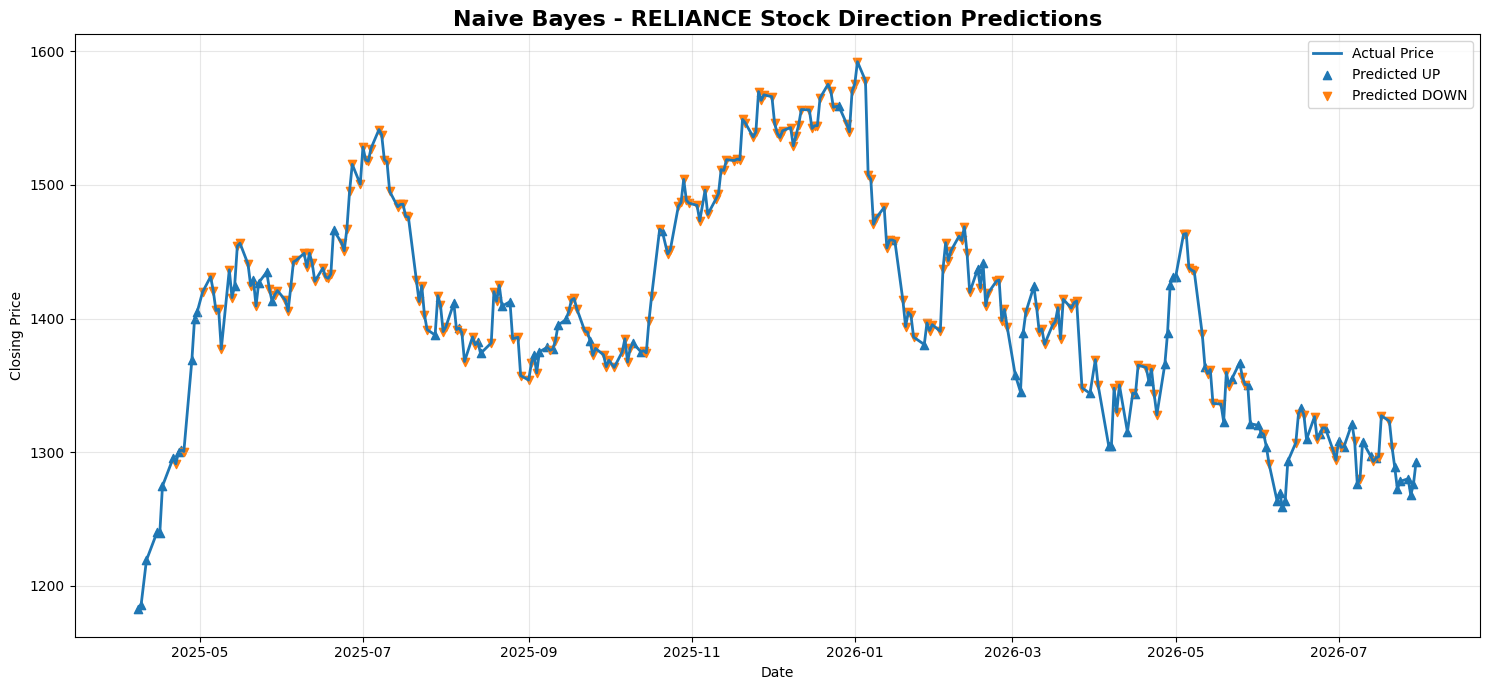

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 7))

# Actual price
plt.plot(
    test_dates,
    test_prices,
    label="Actual Price",
    linewidth=2
)

# Predicted UP
plt.scatter(
    test_dates[naive_bayes_pred == 1],
    test_prices[naive_bayes_pred == 1],
    marker="^",
    s=35,
    label="Predicted UP"
)

# Predicted DOWN
plt.scatter(
    test_dates[naive_bayes_pred == 0],
    test_prices[naive_bayes_pred == 0],
    marker="v",
    s=35,
    label="Predicted DOWN"
)

plt.title(
    "Naive Bayes - RELIANCE Stock Direction Predictions",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Closing Price")

plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()